<a href="https://colab.research.google.com/github/nicolenelson10/credit-card-fraud-detection-ml/blob/feature%2Ffinal-project/FINAL_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning-Based Credit Card Fraud Detection

## Evaluating Model Performance Under Class Imbalance

This project uses Machine Learning to detect fraudulent credit card transactions.

Two classification models are trained and compared:

1. Logistic Regression
2. Random Forest

Each model is trained on two versions of the same dataset:

- **Original imbalanced dataset** (284,807 transactions, only 0.17% fraud)
- **Balanced dataset** (all 492 fraud transactions + 1,000 randomly selected legitimate transactions)

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

The main objective is to understand model performance under severe class imbalance and to compare it with performance on a balanced dataset.

In [1]:
# ---------- Import the libraries ----------
import pandas as pd                # for loading and handling the dataset (tables)
import numpy as np                 # for numerical operations
import matplotlib.pyplot as plt    # for drawing graphs
import seaborn as sns              # for nicer-looking graphs

from sklearn.model_selection import train_test_split   # splits data into training and testing sets
from sklearn.preprocessing import StandardScaler       # scales numeric values to a similar range
from sklearn.linear_model import LogisticRegression    # Model 1
from sklearn.ensemble import RandomForestClassifier    # Model 2

# Metrics used to evaluate the models
from sklearn.metrics import (
    accuracy_score,          # overall correct predictions
    precision_score,         # of predicted frauds, how many were really fraud
    recall_score,            # of real frauds, how many were caught
    f1_score,                # balance between precision and recall
    confusion_matrix,        # table of correct / wrong predictions
    classification_report    # summary of all metrics per class
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# ---------- Global plot style and helper functions ----------
# Run this cell once. It makes all graphs in the notebook look clean and consistent.
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

# Default look of every graph (font sizes, grid, border colour)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "axes.edgecolor": "#CCCCCC",
    "grid.color": "#E6E6E6",
    "grid.linestyle": "--",
    "legend.frameon": False,
})

# Colours used in the graphs
CLASS_COLORS = ["#2E86AB", "#E63946"]            # Legitimate = blue, Fraud = red
MODEL_COLORS = {"Logistic Regression": "#4C78A8", "Random Forest": "#F28E2B"}
DATASET_COLORS = {"Imbalanced": "#9AA5B1", "Balanced": "#2A9D8F"}


def plot_class_distribution(ax, data, title):
    """Bar chart of class counts with count and percentage labels."""
    counts = data["Class"].value_counts().sort_index()   # number of legitimate (0) and fraud (1)
    total = counts.sum()
    bars = ax.bar(["Legitimate", "Fraud"], counts.values, color=CLASS_COLORS,
                  width=0.55, edgecolor="white", linewidth=1.5)
    # Write the count and percentage above each bar
    for bar, value in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + counts.max() * 0.015,
                f"{value:,}\n({value / total * 100:.2f}%)",
                ha="center", va="bottom", fontsize=11, fontweight="bold")
    ax.set_ylim(0, counts.max() * 1.22)    # leave some space above the tallest bar for the label
    ax.set_title(title)
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Transactions")
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)                     # remove top and right border lines


def plot_confusion_matrix(ax, cm, title, cmap="Blues"):
    """Confusion matrix heatmap showing counts and row percentages."""
    # Percentage of each row (percentage of the actual class)
    row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    # Text shown inside each box: count + percentage
    labels = np.array([[f"{cm[i, j]:,}\n({row_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=labels, fmt="", cmap=cmap, cbar=False, square=True,
                linewidths=3, linecolor="white",
                annot_kws={"fontsize": 13, "fontweight": "bold"},
                xticklabels=["Legitimate", "Fraud"], yticklabels=["Legitimate", "Fraud"], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")     # what the model predicted
    ax.set_ylabel("Actual")        # what the transaction really was
    ax.grid(False)


def add_bar_labels(ax, bars, fmt="{:.1f}"):
    """Write the value on top of every bar."""
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
                fmt.format(bar.get_height()), ha="center", va="bottom",
                fontsize=9, fontweight="bold")

print("Plot style loaded!")

In [2]:
# Upload the dataset file (archive.zip) from your computer to Google Colab
from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving archive.zip to archive.zip
Dataset uploaded successfully!


In [3]:
# Unzip archive.zip into a folder called "dataset"
import zipfile
import os

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset extracted successfully!")
print(os.listdir("dataset"))    # show the files inside the folder (should show creditcard.csv)

Dataset extracted successfully!
['creditcard.csv']


In [4]:
# Read the CSV file into a pandas DataFrame called df
df = pd.read_csv("dataset/creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)    # (number of rows, number of columns)

Dataset loaded successfully!
Dataset shape: (284807, 31)


In [5]:
# Show the first 5 rows of the dataset
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
# Show column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
# Count missing values in the whole dataset (0 means no missing values)
print("Missing values:")
print(df.isnull().sum().sum())

Missing values:
0


In [8]:
# Count how many transactions are legitimate (0) and fraud (1)
print("Class Distribution:")
print(df["Class"].value_counts())

# Same thing in percentage - this shows the severe class imbalance
print("\nClass Distribution in Percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class Distribution in Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


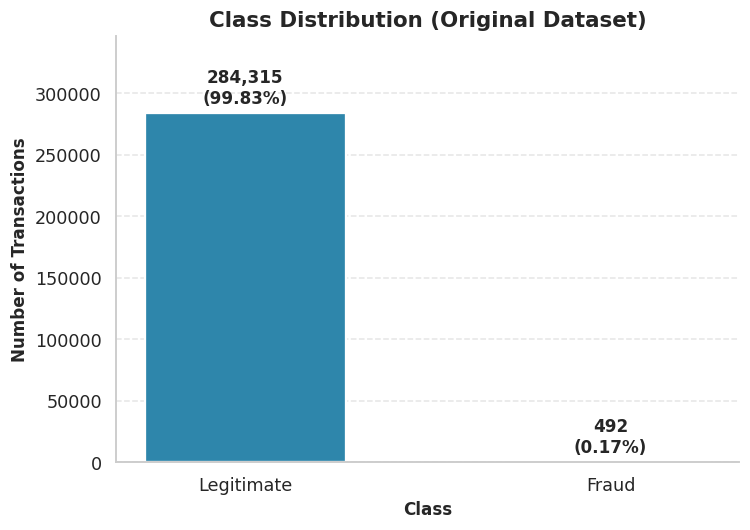

In [ ]:
# Bar chart of legitimate vs fraud transactions in the original dataset
fig, ax = plt.subplots(figsize=(7, 5))
plot_class_distribution(ax, df, "Class Distribution (Original Dataset)")
plt.tight_layout()
plt.show()

## Class Imbalance

The dataset contains 284,807 transactions.

- Legitimate transactions: 284,315 (approximately 99.83%)
- Fraudulent transactions: 492 (approximately 0.17%)

This shows severe class imbalance.

Because fraudulent transactions represent only a very small portion of the dataset, accuracy alone is not sufficient for evaluating fraud detection models.

In [10]:
# X = input features (everything except the Class column)
# y = target / label we want to predict (0 = legitimate, 1 = fraud)
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [11]:
# Split the data: 80% for training and 20% for testing
# random_state=42 gives the same split every time
# stratify=y keeps the same fraud percentage in both training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (227845, 30)
Testing data shape: (56962, 30)


In [12]:
# The Amount column has very large values compared to other columns, so we scale it
scaler = StandardScaler()

# Copy first to avoid changing the original data
X_train = X_train.copy()
X_test = X_test.copy()

# fit_transform on training data: learn the mean/std and scale
# transform on test data: use the same mean/std (avoids data leakage)
X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

print("Amount feature scaled successfully!")

Amount feature scaled successfully!


In [13]:
# Create the Logistic Regression model
# max_iter=5000 gives the model enough steps to converge
# class_weight="balanced" gives more importance to the rare fraud class
lr_model = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42
)

# Train the model using the training data
lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [14]:
# Predict fraud / legitimate for the test data
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression predictions completed!")

Logistic Regression predictions completed!


In [15]:
# Compare the predictions (y_pred_lr) with the real labels (y_test)
lr_accuracy = accuracy_score(y_test, y_pred_lr)     # overall correct predictions
lr_precision = precision_score(y_test, y_pred_lr)   # of predicted frauds, how many were really fraud
lr_recall = recall_score(y_test, y_pred_lr)         # of real frauds, how many were detected
lr_f1 = f1_score(y_test, y_pred_lr)                 # balance of precision and recall

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1-Score : {lr_f1:.4f}")

Logistic Regression Results
---------------------------
Accuracy : 0.9755
Precision: 0.0609
Recall   : 0.9184
F1-Score : 0.1142


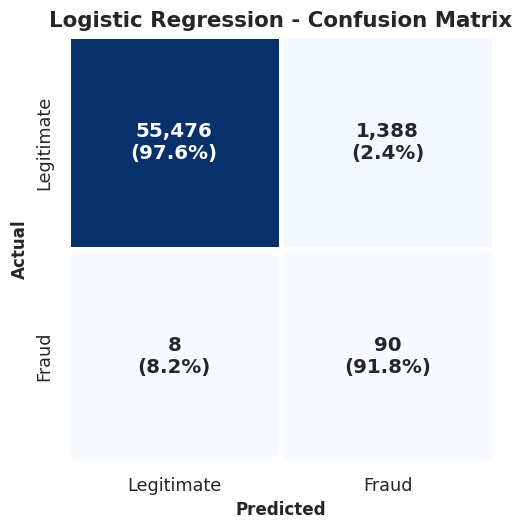

In [ ]:
# Confusion matrix: shows correct and wrong predictions
# (TN, FP on the first row; FN, TP on the second row)
lr_cm = confusion_matrix(y_test, y_pred_lr)

fig, ax = plt.subplots(figsize=(6, 5))
plot_confusion_matrix(ax, lr_cm, "Logistic Regression - Confusion Matrix", cmap="Blues")
plt.tight_layout()
plt.show()

In [17]:
# Precision, recall and F1-score for each class separately
print("Logistic Regression Classification Report")
print("------------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Legitimate", "Fraud"]
    )
)

Logistic Regression Classification Report
------------------------------------------
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [18]:
# Create the Random Forest model
# n_estimators=100 means 100 decision trees
# class_weight="balanced" gives more importance to the rare fraud class
# n_jobs=-1 uses all CPU cores to train faster
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model using the training data
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [19]:
# Predict fraud / legitimate for the test data
y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [20]:
# Compare the predictions (y_pred_rf) with the real labels (y_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-Score : {rf_f1:.4f}")

Random Forest Results
---------------------
Accuracy : 0.9995
Precision: 0.9605
Recall   : 0.7449
F1-Score : 0.8391


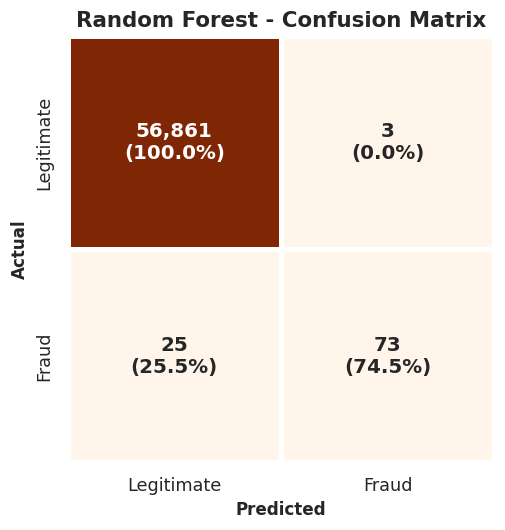

In [ ]:
# Confusion matrix for Random Forest
rf_cm = confusion_matrix(y_test, y_pred_rf)

fig, ax = plt.subplots(figsize=(6, 5))
plot_confusion_matrix(ax, rf_cm, "Random Forest - Confusion Matrix", cmap="Oranges")
plt.tight_layout()
plt.show()

In [22]:
# Precision, recall and F1-score for each class separately
print("Random Forest Classification Report")
print("-----------------------------------")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Legitimate", "Fraud"]
    )
)

Random Forest Classification Report
-----------------------------------
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [23]:
# Put the results of both models in one table
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        rf_accuracy
    ],
    "Precision": [
        lr_precision,
        rf_precision
    ],
    "Recall": [
        lr_recall,
        rf_recall
    ],
    "F1-Score": [
        lr_f1,
        rf_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.975492,0.060893,0.918367,0.114213
1,Random Forest,0.999508,0.960526,0.744898,0.839080


In [24]:
# Convert the scores to percentages (0.9755 -> 97.55) for easier reading
results_percentage = results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    results_percentage[column] *= 100

results_percentage = results_percentage.round(2)

results_percentage.style.hide(axis="index")    # show the table without the row numbers

Model,Accuracy,Precision,Recall,F1-Score
Logistic Regression,97.550000,6.090000,91.840000,11.420000
Random Forest,99.950000,96.050000,74.490000,83.910000


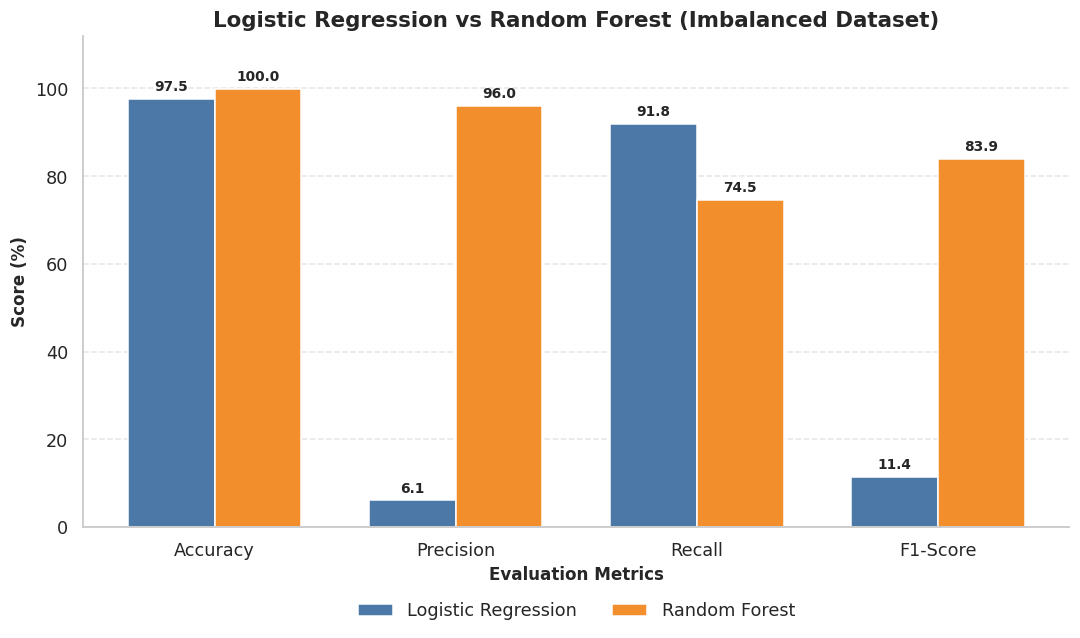

In [ ]:
# Bar chart comparing both models on the imbalanced dataset
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

x = np.arange(len(metrics))    # positions of the groups on the x-axis
width = 0.36                   # width of each bar

fig, ax = plt.subplots(figsize=(10, 6))

# One bar for Logistic Regression and one for Random Forest in every group
bars1 = ax.bar(x - width / 2, results_percentage.loc[0, metrics], width,
               label="Logistic Regression", color=MODEL_COLORS["Logistic Regression"], edgecolor="white")
bars2 = ax.bar(x + width / 2, results_percentage.loc[1, metrics], width,
               label="Random Forest", color=MODEL_COLORS["Random Forest"], edgecolor="white")

add_bar_labels(ax, bars1)    # write the values on top of the bars
add_bar_labels(ax, bars2)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score (%)")
ax.set_xlabel("Evaluation Metrics")
ax.set_title("Logistic Regression vs Random Forest (Imbalanced Dataset)")
ax.set_ylim(0, 112)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

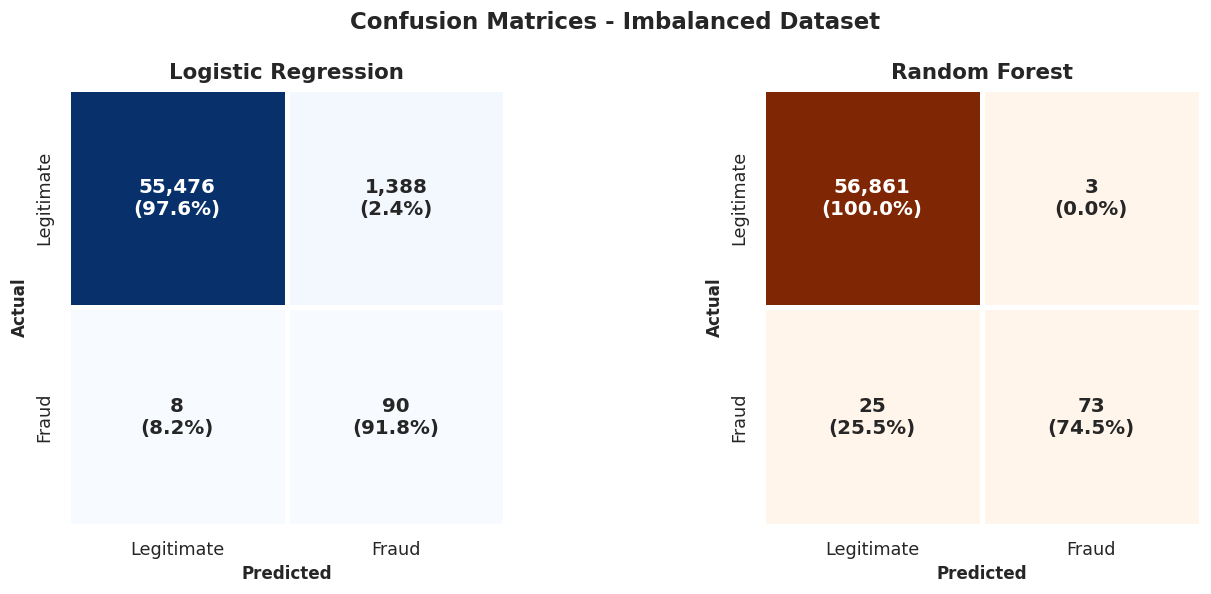

In [ ]:
# Both confusion matrices side by side (imbalanced dataset)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

plot_confusion_matrix(axes[0], lr_cm, "Logistic Regression", cmap="Blues")
plot_confusion_matrix(axes[1], rf_cm, "Random Forest", cmap="Oranges")

fig.suptitle("Confusion Matrices - Imbalanced Dataset", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [27]:
# Take the 4 values out of each confusion matrix
# TN = legitimate predicted legitimate, FP = legitimate predicted fraud (false alarm)
# FN = fraud predicted legitimate (missed fraud), TP = fraud predicted fraud (caught fraud)
lr_tn, lr_fp, lr_fn, lr_tp = lr_cm.ravel()
rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "True Negatives": [lr_tn, rf_tn],
    "False Positives": [lr_fp, rf_fp],
    "False Negatives": [lr_fn, rf_fn],
    "True Positives": [lr_tp, rf_tp]
})

comparison.style.hide(axis="index")

Model,True Negatives,False Positives,False Negatives,True Positives
Logistic Regression,55476,1388,8,90
Random Forest,56861,3,25,73


---
# Part 2: Balanced Dataset Experiment

The results above were obtained on the **original imbalanced dataset**.

To compare, a **balanced version of the same dataset** is created:

- All **492** fraudulent transactions are kept.
- **1,000** legitimate transactions are randomly selected (`random_state=42`).

Everything else is kept the same: 80/20 stratified split, scaling of `Amount`, the same two models and the same hyperparameters, and the same evaluation metrics.

In [ ]:
# Separate fraud and legitimate transactions
fraud_df = df[df["Class"] == 1]    # all 492 fraud transactions
legit_df = df[df["Class"] == 0]    # all legitimate transactions (284,315)

# Randomly select only 1000 legitimate transactions
# random_state=42 gives the same random selection every time
legit_sample_df = legit_df.sample(n=1000, random_state=42)

# Combine fraud + 1000 legitimate rows, then shuffle the rows
# frac=1 means "use all rows", so this only shuffles them
balanced_df = (
    pd.concat([fraud_df, legit_sample_df])
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("Balanced dataset shape:", balanced_df.shape)

print("\nClass Distribution (Balanced Dataset):")
print(balanced_df["Class"].value_counts())

print("\nClass Distribution in Percentage (Balanced Dataset):")
print(balanced_df["Class"].value_counts(normalize=True) * 100)

In [ ]:
# Compare the class distribution of the original and the balanced dataset
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_class_distribution(axes[0], df, "Original Dataset (Imbalanced)")
plot_class_distribution(axes[1], balanced_df, "Balanced Dataset (1000 Legitimate + 492 Fraud)")

plt.tight_layout()
plt.show()

In [ ]:
# Features (X_bal) and target (y_bal) of the balanced dataset
X_bal = balanced_df.drop("Class", axis=1)
y_bal = balanced_df["Class"]

# Same 80/20 stratified split as before
X_train_bal, X_test_bal, y_train_bal, y_test_bal = train_test_split(
    X_bal,
    y_bal,
    test_size=0.2,
    random_state=42,
    stratify=y_bal
)

print("Training data shape:", X_train_bal.shape)
print("Testing data shape:", X_test_bal.shape)

# Scale the Amount column (learn the scaling from training data only)
scaler_bal = StandardScaler()

X_train_bal = X_train_bal.copy()
X_test_bal = X_test_bal.copy()

X_train_bal["Amount"] = scaler_bal.fit_transform(X_train_bal[["Amount"]])
X_test_bal["Amount"] = scaler_bal.transform(X_test_bal[["Amount"]])

print("Amount feature scaled successfully!")

## Logistic Regression - Balanced Dataset

In [ ]:
# Logistic Regression with the same settings, now trained on the balanced dataset
lr_model_bal = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42
)

lr_model_bal.fit(X_train_bal, y_train_bal)           # train
y_pred_lr_bal = lr_model_bal.predict(X_test_bal)     # predict on balanced test data

# Calculate the metrics
lr_accuracy_bal = accuracy_score(y_test_bal, y_pred_lr_bal)
lr_precision_bal = precision_score(y_test_bal, y_pred_lr_bal)
lr_recall_bal = recall_score(y_test_bal, y_pred_lr_bal)
lr_f1_bal = f1_score(y_test_bal, y_pred_lr_bal)

print("Logistic Regression Results (Balanced Dataset)")
print("----------------------------------------------")
print(f"Accuracy : {lr_accuracy_bal:.4f}")
print(f"Precision: {lr_precision_bal:.4f}")
print(f"Recall   : {lr_recall_bal:.4f}")
print(f"F1-Score : {lr_f1_bal:.4f}")

In [ ]:
# Confusion matrix for Logistic Regression (balanced dataset)
lr_cm_bal = confusion_matrix(y_test_bal, y_pred_lr_bal)

fig, ax = plt.subplots(figsize=(6, 5))
plot_confusion_matrix(ax, lr_cm_bal, "Logistic Regression - Confusion Matrix (Balanced)", cmap="Blues")
plt.tight_layout()
plt.show()

# Classification report for each class
print("Logistic Regression Classification Report (Balanced Dataset)")
print("------------------------------------------------------------")
print(
    classification_report(
        y_test_bal,
        y_pred_lr_bal,
        target_names=["Legitimate", "Fraud"]
    )
)

## Random Forest - Balanced Dataset

In [ ]:
# Random Forest with the same settings, now trained on the balanced dataset
rf_model_bal = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model_bal.fit(X_train_bal, y_train_bal)           # train
y_pred_rf_bal = rf_model_bal.predict(X_test_bal)     # predict on balanced test data

# Calculate the metrics
rf_accuracy_bal = accuracy_score(y_test_bal, y_pred_rf_bal)
rf_precision_bal = precision_score(y_test_bal, y_pred_rf_bal)
rf_recall_bal = recall_score(y_test_bal, y_pred_rf_bal)
rf_f1_bal = f1_score(y_test_bal, y_pred_rf_bal)

print("Random Forest Results (Balanced Dataset)")
print("----------------------------------------")
print(f"Accuracy : {rf_accuracy_bal:.4f}")
print(f"Precision: {rf_precision_bal:.4f}")
print(f"Recall   : {rf_recall_bal:.4f}")
print(f"F1-Score : {rf_f1_bal:.4f}")

In [ ]:
# Confusion matrix for Random Forest (balanced dataset)
rf_cm_bal = confusion_matrix(y_test_bal, y_pred_rf_bal)

fig, ax = plt.subplots(figsize=(6, 5))
plot_confusion_matrix(ax, rf_cm_bal, "Random Forest - Confusion Matrix (Balanced)", cmap="Oranges")
plt.tight_layout()
plt.show()

# Classification report for each class
print("Random Forest Classification Report (Balanced Dataset)")
print("------------------------------------------------------")
print(
    classification_report(
        y_test_bal,
        y_pred_rf_bal,
        target_names=["Legitimate", "Fraud"]
    )
)

## Comparison: Imbalanced vs Balanced Dataset

In [ ]:
# One table with the results of both models on both datasets
comparison_all = pd.DataFrame({
    "Dataset": [
        "Imbalanced", "Balanced",
        "Imbalanced", "Balanced"
    ],
    "Model": [
        "Logistic Regression", "Logistic Regression",
        "Random Forest", "Random Forest"
    ],
    "Accuracy": [lr_accuracy, lr_accuracy_bal, rf_accuracy, rf_accuracy_bal],
    "Precision": [lr_precision, lr_precision_bal, rf_precision, rf_precision_bal],
    "Recall": [lr_recall, lr_recall_bal, rf_recall, rf_recall_bal],
    "F1-Score": [lr_f1, lr_f1_bal, rf_f1, rf_f1_bal]
})

# Convert to percentages for easier reading
comparison_all_pct = comparison_all.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    comparison_all_pct[column] = (comparison_all_pct[column] * 100).round(2)

comparison_all_pct.style.hide(axis="index")

In [ ]:
# Bar charts: imbalanced vs balanced for each model
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
x = np.arange(len(metrics))    # positions of the groups on the x-axis
width = 0.36                   # width of each bar

# Two graphs side by side (one per model) sharing the same y-axis
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for ax, model_name in zip(axes, ["Logistic Regression", "Random Forest"]):
    # Take only the rows of this model from the comparison table
    subset = comparison_all_pct[comparison_all_pct["Model"] == model_name]
    imb = subset[subset["Dataset"] == "Imbalanced"][metrics].values.flatten()
    bal = subset[subset["Dataset"] == "Balanced"][metrics].values.flatten()

    bars1 = ax.bar(x - width / 2, imb, width, label="Imbalanced",
                   color=DATASET_COLORS["Imbalanced"], edgecolor="white")
    bars2 = ax.bar(x + width / 2, bal, width, label="Balanced",
                   color=DATASET_COLORS["Balanced"], edgecolor="white")

    add_bar_labels(ax, bars1)    # write the values on top of the bars
    add_bar_labels(ax, bars2)

    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_title(model_name)
    ax.set_xlabel("Evaluation Metrics")
    ax.set_ylim(0, 112)
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

axes[0].set_ylabel("Score (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))   # one legend for both graphs
fig.suptitle("Imbalanced vs Balanced Dataset", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.show()

In [ ]:
# Both confusion matrices side by side (balanced dataset)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

plot_confusion_matrix(axes[0], lr_cm_bal, "Logistic Regression (Balanced)", cmap="Blues")
plot_confusion_matrix(axes[1], rf_cm_bal, "Random Forest (Balanced)", cmap="Oranges")

fig.suptitle("Confusion Matrices - Balanced Dataset", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Take the 4 values (TN, FP, FN, TP) out of each confusion matrix
lr_tn_b, lr_fp_b, lr_fn_b, lr_tp_b = lr_cm_bal.ravel()
rf_tn_b, rf_fp_b, rf_fn_b, rf_tp_b = rf_cm_bal.ravel()

comparison_bal = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "True Negatives": [lr_tn_b, rf_tn_b],
    "False Positives": [lr_fp_b, rf_fp_b],
    "False Negatives": [lr_fn_b, rf_fn_b],
    "True Positives": [lr_tp_b, rf_tp_b]
})

comparison_bal.style.hide(axis="index")

In [ ]:
# Print how each metric changed from the imbalanced to the balanced dataset
print("Accuracy Comparison")
print("-------------------")
print(f"Logistic Regression | Imbalanced: {lr_accuracy*100:.2f}%  ->  Balanced: {lr_accuracy_bal*100:.2f}%")
print(f"Random Forest       | Imbalanced: {rf_accuracy*100:.2f}%  ->  Balanced: {rf_accuracy_bal*100:.2f}%")

print("\nPrecision Comparison")
print("--------------------")
print(f"Logistic Regression | Imbalanced: {lr_precision*100:.2f}%  ->  Balanced: {lr_precision_bal*100:.2f}%")
print(f"Random Forest       | Imbalanced: {rf_precision*100:.2f}%  ->  Balanced: {rf_precision_bal*100:.2f}%")

print("\nRecall Comparison")
print("-----------------")
print(f"Logistic Regression | Imbalanced: {lr_recall*100:.2f}%  ->  Balanced: {lr_recall_bal*100:.2f}%")
print(f"Random Forest       | Imbalanced: {rf_recall*100:.2f}%  ->  Balanced: {rf_recall_bal*100:.2f}%")

print("\nF1-Score Comparison")
print("-------------------")
print(f"Logistic Regression | Imbalanced: {lr_f1*100:.2f}%  ->  Balanced: {lr_f1_bal*100:.2f}%")
print(f"Random Forest       | Imbalanced: {rf_f1*100:.2f}%  ->  Balanced: {rf_f1_bal*100:.2f}%")

# Interpretation - Imbalanced vs Balanced Dataset

In the original dataset, fraudulent transactions are only about 0.17% of all transactions. A model can reach very high accuracy there simply because almost every transaction is legitimate, so accuracy alone does not show how well fraud is actually detected.

In the balanced dataset (492 fraud and 1,000 legitimate transactions), fraud makes up about one third of the data. The models see far more fraud examples relative to legitimate ones, so the precision, recall and F1-score for the fraud class are no longer dominated by the huge legitimate majority.

Points to note when comparing the two sets of results:

- The two experiments use **different test sets**. The imbalanced test set has 56,962 transactions (98 fraud), while the balanced test set has 299 transactions (about 98 fraud). The numbers are therefore not a perfectly like-for-like comparison.
- Accuracy on the imbalanced dataset is inflated by the legitimate majority class, whereas accuracy on the balanced dataset reflects performance on both classes more fairly.
- The balanced dataset uses only 1,000 of the 284,315 legitimate transactions, so a lot of legitimate data is not used. Results on a small balanced test set can also vary with the random sample.

Refer to the comparison table and charts above for the exact values of Accuracy, Precision, Recall and F1-Score before and after balancing.

# Interpretation - Imbalanced Dataset

The dataset is highly imbalanced, with fraudulent transactions representing only approximately 0.17% of all transactions.

Logistic Regression achieved an accuracy of approximately 97.55%, precision of 6.09%, recall of 91.84%, and F1-score of 11.42%.

Random Forest achieved an accuracy of approximately 99.95%, precision of 96.05%, recall of 74.49%, and F1-score of 83.91%.

Logistic Regression achieved higher recall, meaning it detected a larger proportion of the actual fraudulent transactions. However, it produced a much larger number of false positive alerts.

Random Forest produced significantly fewer false positives and achieved higher precision and F1-score. However, its recall was lower, meaning it missed more fraudulent transactions than Logistic Regression.

These results demonstrate that fraud detection involves a trade-off between detecting more fraudulent transactions and reducing false alarms.

Therefore, accuracy alone should not be used to evaluate models on highly imbalanced datasets. Precision, recall, F1-score, and the confusion matrix provide a more complete understanding of model performance.

# Conclusion

In this project, we developed and evaluated two Machine Learning models for credit card fraud detection: Logistic Regression and Random Forest.

The original dataset contained severe class imbalance (about 0.17% fraud), making traditional accuracy-based evaluation insufficient. To compare, a balanced version of the same dataset was created using all 492 fraudulent transactions and 1,000 randomly selected legitimate transactions.

Both models were trained and evaluated on both versions of the dataset using the same preprocessing procedure, the same hyperparameters and the same stratified 80/20 split. Their performance was compared using Accuracy, Precision, Recall, F1-Score and Confusion Matrix.

The comparison shows how class imbalance affects the reported metrics: accuracy on the imbalanced data is high mainly because of the legitimate majority class, while precision, recall and F1-score give a more complete view of how well fraud is detected.

This project highlights the importance of selecting appropriate evaluation metrics, and of considering how the class distribution affects the results, when working with highly imbalanced classification problems.